# Gotoh Affine Gaps

Opening a gap and extending an existing gap can carry different costs. Three dynamic-programming states remember which operation ended the aligned prefix.

This example minimises cost. A gap of length L costs 3 + L and a mismatch costs 2. The gap of length one therefore costs 4. The same convention is used in the independent comparison.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import gotoh
from Bio.Align import PairwiseAligner

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Optimal cost 7 | length-one gap costs 4


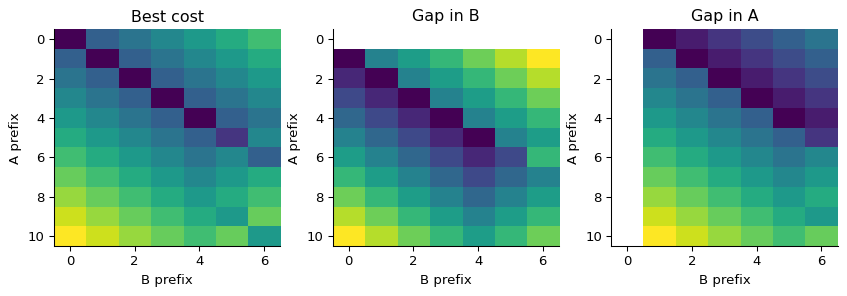

In [2]:
a, b = "ACGTTTTTAC", "ACGTAC"
cost, H, D, I = gotoh(a, b)
check = PairwiseAligner(
    mode="global", match_score=0, mismatch_score=-2, open_gap_score=-4, extend_gap_score=-1
)
assert cost == -check.score(a, b)
print("Optimal cost", cost, "| length-one gap costs 4")
fig, axes = plt.subplots(1, 3, figsize=(8.8, 3), constrained_layout=True)
for ax, m, title in zip(axes, [H, D, I], ["Best cost", "Gap in B", "Gap in A"]):
    ax.imshow(np.ma.masked_invalid(m), aspect="auto", cmap="viridis")
    ax.set(title=title, xlabel="B prefix", ylabel="A prefix")
plt.show()

## Interpreting the result

A long gap becomes cheaper per omitted base as its opening penalty is shared. Blank boundary cells are unreachable states.

## Exercise

Find a mismatch penalty at which two separate gaps become competitive with a substitution.

## References

[Gotoh, affine gap alignment (1982)](https://doi.org/10.1016/0022-2836(82)90398-9)

[Biopython, pairwise alignments](https://biopython.org/docs/latest/Tutorial/chapter_pairwise.html)